In [5]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("..").resolve()
conn = sqlite3.connect(BASE / "Data" / "db" / "bluestock_mf.db")
CHART_DIR = BASE / "Reports" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

scorecard = pd.read_csv(BASE / "Data" / "processed" / "fund_scorecard.csv",
                        dtype={"amfi_code": str})
print("Scorecard rows:", len(scorecard))
scorecard.head(3)

Scorecard rows: 40


,category,scheme_name,amfi_code,score,cagr_3yr_pct,sharpe,alpha_ann_pct,expense_ratio_pct,max_drawdown_pct
0,Debt,ICICI Pru Liquid Fund - Regular - Growth,120507,92.5,7.063477,0.962198,6.746210,0.74,-0.097731
1,Debt,Kotak Liquid Fund - Regular - Growth,120844,80.8,6.555139,0.321465,6.455677,0.60,-0.116293
2,Debt,ABSL Liquid Fund - Regular - Growth,101208,50.8,6.080205,-0.446459,6.086146,0.79,-0.162250


Days compared: 784 | from 2023-05-30 to 2026-05-29
                           fund  3yr_growth_pct  tracking_error_pct
     Mirae Asset Large Cap Fund          141.49               18.81
HDFC Mid-Cap Opportunities Fund          132.34               22.51
          ICICI Pru Midcap Fund          127.49               23.28
            Kotak Flexicap Fund          118.14               20.67
               Axis Midcap Fund          147.87               23.99


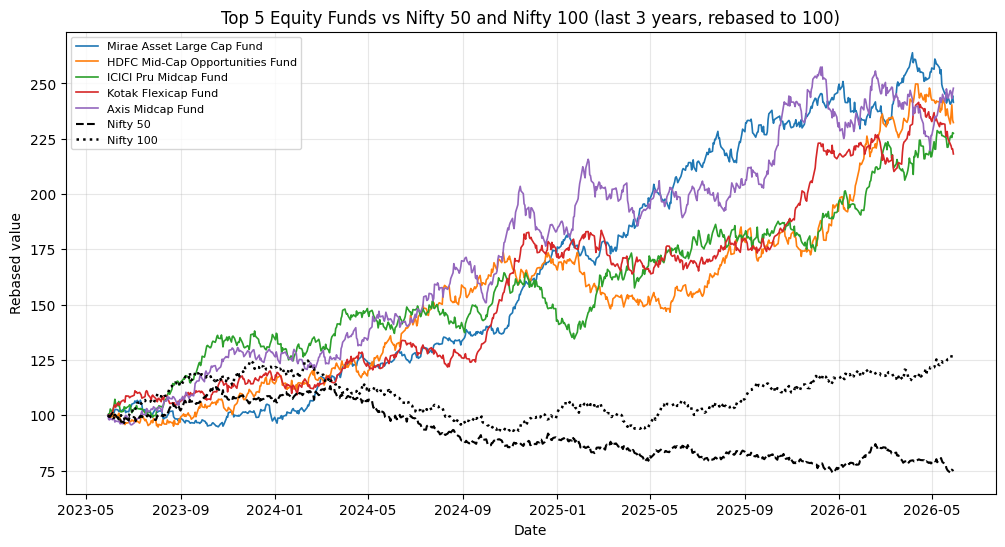

In [2]:
# Top 5 equity funds from the scorecard
top5 = scorecard[scorecard["category"] == "Equity"].head(5)
codes = top5["amfi_code"].tolist()
short = dict(zip(codes, top5["scheme_name"].str.split(" - ").str[0]))

# Fund NAVs
nav = pd.read_sql_query("SELECT amfi_code, date, nav FROM fact_nav",
                        conn, parse_dates=["date"])
nav["amfi_code"] = nav["amfi_code"].astype(str)
fund_wide = nav[nav["amfi_code"].isin(codes)].pivot(
    index="date", columns="amfi_code", values="nav")

# Benchmark index values
bm = pd.read_sql_query(
    "SELECT date, index_name, close_value FROM fact_benchmark "
    "WHERE index_name IN ('NIFTY50', 'NIFTY100')",
    conn, parse_dates=["date"])
bm_wide = bm.pivot(index="date", columns="index_name", values="close_value")

# Join on common dates and keep the last 3 years
data = fund_wide.join(bm_wide, how="inner").dropna()
cutoff = data.index.max() - pd.Timedelta(days=3 * 365)
data = data.loc[data.index >= cutoff]
print("Days compared:", len(data), "| from", data.index.min().date(),
      "to", data.index.max().date())

# Tracking error: std of (fund daily return - Nifty 100 daily return), annualised
daily = data.pct_change().dropna()
tracking = (daily[codes].sub(daily["NIFTY100"], axis=0).std() * np.sqrt(252) * 100)

summary = pd.DataFrame({
    "fund": [short[c] for c in codes],
    "3yr_growth_pct": ((data[codes].iloc[-1] / data[codes].iloc[0] - 1) * 100).round(2).values,
    "tracking_error_pct": tracking.round(2).values,
})
print(summary.to_string(index=False))

# Chart: everything rebased to 100 at the start
rebased = data / data.iloc[0] * 100
fig, ax = plt.subplots(figsize=(12, 6))
for c in codes:
    ax.plot(rebased.index, rebased[c], linewidth=1.2, label=short[c])
ax.plot(rebased.index, rebased["NIFTY50"], "k--", linewidth=1.5, label="Nifty 50")
ax.plot(rebased.index, rebased["NIFTY100"], "k:", linewidth=1.8, label="Nifty 100")
ax.set_title("Top 5 Equity Funds vs Nifty 50 and Nifty 100 (last 3 years, rebased to 100)")
ax.set_xlabel("Date")
ax.set_ylabel("Rebased value")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.savefig(CHART_DIR / "12_benchmark_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
idx = pd.read_sql_query(
    """
    SELECT index_name,
           MIN(date) AS first_date,
           MAX(date) AS last_date,
           MIN(close_value) AS lowest,
           MAX(close_value) AS highest
    FROM fact_benchmark
    GROUP BY index_name
    """,
    conn
)
print(idx.to_string(index=False))

     index_name first_date  last_date   lowest  highest
   BSE_SMALLCAP 2022-01-03 2026-05-29 23592.64 79075.39
    CRISIL_GILT 2022-01-03 2026-05-29  1444.13  2302.79
  CRISIL_LIQUID 2022-01-03 2026-05-29  2281.51  3046.00
       NIFTY100 2022-01-03 2026-05-29 14128.86 21088.58
        NIFTY50 2022-01-03 2026-05-29 17492.79 27798.72
       NIFTY500 2022-01-03 2026-05-29 14426.04 38418.87
NIFTY_MIDCAP150 2022-01-03 2026-05-29  8980.60 32990.66


In [4]:
bm_all = pd.read_sql_query(
    "SELECT date, index_name, close_value FROM fact_benchmark",
    conn, parse_dates=["date"]
)
w = bm_all.pivot(index="date", columns="index_name", values="close_value")
r = w.pct_change().dropna()
print(r[["NIFTY50", "NIFTY100", "NIFTY500", "NIFTY_MIDCAP150"]].corr().round(2))

index_name       NIFTY50  NIFTY100  NIFTY500  NIFTY_MIDCAP150
index_name                                                   
NIFTY50             1.00     -0.05     -0.00             0.01
NIFTY100           -0.05      1.00      0.03             0.00
NIFTY500           -0.00      0.03      1.00             0.00
NIFTY_MIDCAP150     0.01      0.00      0.00             1.00
